# Particle Physics Cosmic Muon Simulation

## This is a simulation for incident cosmic muons for the 1st year of the particle physics masters at UNIGE

### Authors: Taylor Rayne Andrade and José Javier Acuña Muñoz

In [6]:
import numpy as np
import matplotlib.pyplot as plt
me= 0.511  #Actually mec^2. MeV Take c=1
K = 0.307075  # MeV mol^-1 cm^2, consant

materials = {

    "plexiglass" :{
        "ZA": 0.53937,
        "I": 74.0,
        "rho": 1.190,
        "state": "condensed"
    },

    "air": {
        "ZA": 0.49919,
        "I": 85.7,
        "rho": 0.001205,
        "state": "gas"
    },

    "lead": {
        "ZA": 82/207.2,
        "I": 823,
        "rho": 11.35,
        "state": "condensed"
    },

    "scintillator": {
        "ZA": 0.53768,
        "I": 68.7,
        "rho": 1.060,
        "state": "condensed"
    },

    "copper": {
        "ZA": 29/63.546,
        "I": 322,
        "rho": 8.960,
        "state": "condensed"
    }
}


def sample_muons(n_events=15, seed=112026):
    rng = np.random.default_rng(seed)
    u = rng.random(n_events)

def W_max(beta, gamma, M):
    return (2*me*beta**2*gamma**2)/(1 + 2*gamma*me/M + (me/M)**2)



def density_effect(beta, gamma, X0, X1, a, m, C):
    X = np.log10(beta*gamma)
    if X < X0:
        delta = 0
    elif X0 <= X < X1:
        delta = 4.6052 * X - C + a * (X1 - X)**m
    else:
        delta = 4.6052 * X - C
    return delta

def matter_dependent_parameters(material):

    I = materials[material]["I"]
    ZA = materials[material]["ZA"]
    rho = materials[material]["rho"]
    state = materials[material]["state"]

    plasma_energy = 28.816*np.sqrt(rho*ZA)

    C = 1 + 2*np.log(I/plasma_energy)
    Xa = C/4.606
    m = 3

    # Condensed media (solids and liquids)
    if state == "condensed":

        if I < 100:
            X1 = 2

            if C <= 3.681:
                X0 = 0.2
            else:
                X0 = 0.326*C - 1

        else:
            X1 = 3

            if C <= 5.215:
                X0 = 0.2
            else:
                X0 = 0.326*C - 1.5

    # Gaseous media
    elif state == "gas":

        if C < 10:
            X0 = 1.6
            X1 = 4

        elif C < 10.5:
            X0 = 1.7
            X1 = 4

        elif C < 11:
            X0 = 1.8
            X1 = 4

        elif C < 11.5:
            X0 = 1.9
            X1 = 4

        elif C < 12.25:
            X0 = 2
            X1 = 4

        elif C < 13.804:
            X0 = 2
            X1 = 5

        else:
            X0 = 0.326*C - 2.5
            X1 = 5

    else:
        raise ValueError("Unknown state of matter")

    a = 4.606*(Xa - X0)/(X1 - X0)**m

    return X0, X1, a, m, C
    


def bethe_bloch_diff(z, beta, material): #this does get multiplied by the density of the material to get the stopping power in MeV/cm. The z is the charge of the incident particle, beta is v/c, and material is a string that specifies the material.

    M_muon = 105.658 # MeV/c^2
 
    ZA = materials[material]["ZA"] #ratio of Z/A as it gets a lil complicated with mixtures such as air + scintillators.
    I = materials[material]["I"]*1e-6
    rho = materials[material]["rho"]

    gamma = 1/np.sqrt(1-beta**2) #Lorentz factor
    W = W_max(beta, gamma, M_muon) # Maximum energy transfer

    X0, X1, a, m, C = matter_dependent_parameters(material)

    delta = density_effect(beta, gamma, X0, X1, a, m, C)

    return rho*(K*z**2*ZA/beta**2)*(0.5*np.log(2*me*beta**2*gamma**2*W/I**2)- beta**2- delta/2)


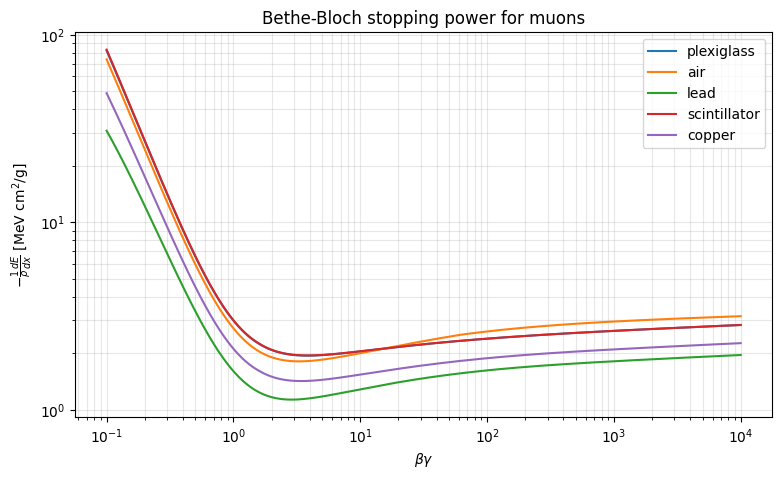

In [ ]:
beta_gamma = np.logspace(-1, 4, 1000) #beta times gamma, from 0.1 to 10^4

gamma = np.sqrt(1 + beta_gamma**2)
beta = beta_gamma/gamma

plt.figure(figsize=(9, 5))

for material in materials:
    dEdx = np.array([bethe_bloch_diff(1, b, material)for b in beta])

    rho = materials[material]["rho"]

    plt.plot(beta_gamma, dEdx/rho, label=material)

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$\beta\gamma$")
plt.ylabel(r"$-\frac{1}{\rho}\frac{dE}{dx}$ [MeV cm$^2$/g]")
plt.title("Bethe-Bloch stopping power for muons")
plt.legend()
plt.grid(which="both", alpha=0.3)
plt.show()